# Лабораторная работа №3. Оптимизация гиперпараметров

## 1. Выбор задачи и модели

Используется задача регрессии из лабораторной работы №1: предсказание оценки качества вина по физико-химическим характеристикам. Красные и белые вина объединяются в один набор данных, дополнительно добавляется признак `is_red`.

В качестве алгоритма выбран случайный лес регрессии (`RandomForestRegressor`). Он состоит из нескольких деревьев решений, а итоговый прогноз формируется усреднением прогнозов отдельных деревьев.

Исходные параметры модели фиксируются отдельно и используются как baseline. Они не меняются в ходе эксперимента.

In [1]:
from pathlib import Path
import time
import warnings
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from scipy.stats import randint, uniform

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    train_test_split, KFold, GridSearchCV,
    RandomizedSearchCV, cross_validate
)
from sklearn.metrics import mean_squared_error, mean_absolute_error

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42
N_SPLITS = 5
SCORING = "neg_root_mean_squared_error"

## 2. Загрузка и подготовка данных

Загружаются два файла Wine Quality: для красного и белого вина. После объединения создаётся бинарный признак `is_red`: 1 — красное вино, 0 — белое. Полные дубликаты удаляются.

In [2]:
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

urls = {
    "winequality-red.csv": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv",
    "winequality-white.csv": "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv",
}

for filename, url in urls.items():
    path = DATA_DIR / filename
    if not path.exists():
        print("Скачиваю:", filename)
        urllib.request.urlretrieve(url, path)

red = pd.read_csv(DATA_DIR / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA_DIR / "winequality-white.csv", sep=";")

raw_data = pd.concat(
    [red.assign(is_red=1), white.assign(is_red=0)],
    ignore_index=True
)

print("Исходный размер:", raw_data.shape)
print("Количество полных дубликатов:", raw_data.duplicated().sum())

data = raw_data.drop_duplicates().reset_index(drop=True)

print("Размер после удаления дубликатов:", data.shape)
print("Количество пропусков:", data.isna().sum().sum())
display(data.head())

Исходный размер: (6497, 13)
Количество полных дубликатов: 1177
Размер после удаления дубликатов: (5320, 13)
Количество пропусков: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5,1


## 3. Разделение данных на обучающую и тестовую выборки

20% данных выделяется в тестовую выборку, остальные 80% используются для обучения и подбора гиперпараметров. `random_state=42` обеспечивает воспроизводимость разбиения.

Тестовая выборка не используется ни в Grid Search, ни в Random Search, ни при выборе гиперпараметров.

In [3]:
X = data.drop(columns="quality")
y = data["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

cv = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

Обучающая выборка: (4256, 12)
Тестовая выборка: (1064, 12)


## 4. Исходная модель (baseline)

Исходная модель — Random Forest с параметрами, зафиксированными в предыдущем эксперименте:

- `n_estimators=500`;
- `max_features=0.8`;
- `min_samples_leaf=2`;
- `random_state=42`.

Baseline оценивается на тех же пяти folds, что и оптимизированные модели. Дополнительно сохраняются ошибки на обучающих частях folds, чтобы сопоставить их с ошибками на проверочных folds.

In [4]:
baseline_params = {
    "n_estimators": 500,
    "max_features": 0.8,
    "min_samples_leaf": 2,
    "random_state": RANDOM_STATE,
    "n_jobs": -1
}

baseline_model = RandomForestRegressor(**baseline_params)

baseline_cv = cross_validate(
    baseline_model,
    X_train, y_train,
    cv=cv,
    scoring=SCORING,
    return_train_score=True,
    n_jobs=1
)

baseline_fold_rmse = -baseline_cv["test_score"]
baseline_cv_rmse = baseline_fold_rmse.mean()

print("Исходные параметры:")
print(baseline_params)
print(f"Средний CV RMSE: {baseline_cv_rmse:.4f}")
print(f"Стандартное отклонение CV RMSE: {baseline_fold_rmse.std(ddof=1):.4f}")
print("RMSE по folds:", np.round(baseline_fold_rmse, 4))

Исходные параметры:
{'n_estimators': 500, 'max_features': 0.8, 'min_samples_leaf': 2, 'random_state': 42, 'n_jobs': -1}
Средний CV RMSE: 0.6958
Стандартное отклонение CV RMSE: 0.0185
RMSE по folds: [0.7189 0.7107 0.6901 0.674  0.6853]


## 5. Гиперпараметры

Для исследования выбраны четыре гиперпараметра:

| Гиперпараметр | Смысл | Проверяемые значения | Ожидаемое влияние |
|---|---|---|---|
| `n_estimators` | Количество деревьев в лесу | 400, 700, 1000 | Большее число деревьев может стабилизировать усреднение, но увеличивает время обучения |
| `max_features` | Доля признаков, рассматриваемых при поиске разбиения | 0.4, 0.6, 0.8 | Управляет случайностью и разнообразием деревьев |
| `max_depth` | Максимальная глубина дерева | 20, без ограничения (`None`) | Ограничение глубины уменьшает сложность дерева; слишком сильное ограничение может привести к недообучению |
| `min_samples_leaf` | Минимальное число объектов в листе | 1, 2 | Увеличение значения сглаживает прогнозы и может уменьшить переобучение |


## 6. Кросс-валидация

Используется 5-fold кросс-валидация с перемешиванием данных (`shuffle=True`). На каждом шаге четыре части обучающей выборки используются для обучения, а оставшаяся часть — для проверки. Процедура повторяется пять раз, и итоговая оценка усредняется.

**Зачем нужна кросс-валидация?** Она позволяет оценить качество модели на нескольких разбиениях обучающих данных, а не делать вывод по одному случайному разбиению.

**Почему одного train/test недостаточно для подбора параметров?** При одном разбиении результат может зависеть от того, какие объекты случайно попали в проверочную часть. Кросс-валидация даёт более устойчивую оценку.

**Что произойдёт, если многократно выбирать параметры по test?** Подбор постепенно начнёт подстраиваться под тестовую выборку. Она перестанет быть независимой оценкой качества на новых данных. Поэтому test используется только после завершения подбора.

## 7. Grid Search — поиск по сетке

Grid Search перебирает все комбинации заданных значений. Для каждой комбинации рассчитывается средняя метрика на пяти folds. В этой работе проверяется 36 комбинаций.

Ниже приведён исходный блок Grid Search. Пространство поиска и параметры этого блока сохранены без изменений.

In [ ]:
param_grid = {
    "n_estimators": [400, 700, 1000],
    "max_features": [0.4, 0.6, 0.8],
    "max_depth": [None, 20],
    "min_samples_leaf": [1, 2]
}

grid_model = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

grid_search = GridSearchCV(
    estimator=grid_model,
    param_grid=param_grid,
    scoring=SCORING,
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

grid_start = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_time = time.perf_counter() - grid_start

grid_best_cv_rmse = -grid_search.best_score_
grid_combinations = len(grid_search.cv_results_["params"])

print("Проверено комбинаций:", grid_combinations)
print("Лучшие параметры:", grid_search.best_params_)
print(f"Лучшая CV RMSE: {grid_best_cv_rmse:.4f}")
print(f"Время Grid Search: {grid_time:.1f} сек.")

grid_results = pd.DataFrame(grid_search.cv_results_)
grid_results["mean_test_RMSE"] = -grid_results["mean_test_score"]
grid_results["std_test_RMSE"] = grid_results["std_test_score"]
grid_results["mean_train_RMSE"] = -grid_results["mean_train_score"]
display(
    grid_results[
        ["params", "mean_train_RMSE", "mean_test_RMSE",
         "std_test_RMSE", "mean_fit_time"]
    ].sort_values("mean_test_RMSE").head(10).round(4)
)

Проверено комбинаций: 36
Лучшие параметры: {'max_depth': None, 'max_features': 0.4, 'min_samples_leaf': 1, 'n_estimators': 400}
Лучшая CV RMSE: 0.6903
Время Grid Search: 245.5 сек.


,params,mean_train_RMSE,mean_test_RMSE,std_test_RMSE,mean_fit_time
0,"{'max_depth': None, 'max_features': 0.4, 'min_...",0.2560,0.6903,0.0164,2.9726
1,"{'max_depth': None, 'max_features': 0.4, 'min_...",0.2555,0.6907,0.0158,7.6840
2,"{'max_depth': None, 'max_features': 0.4, 'min_...",0.2553,0.6907,0.0158,9.2367
19,"{'max_depth': 20, 'max_features': 0.4, 'min_sa...",0.2636,0.6911,0.0165,6.4105
18,"{'max_depth': 20, 'max_features': 0.4, 'min_sa...",0.2642,0.6911,0.0171,7.7980
20,"{'max_depth': 20, 'max_features': 0.4, 'min_sa...",0.2633,0.6911,0.0163,10.9494
5,"{'max_depth': None, 'max_features': 0.4, 'min_...",0.3492,0.6912,0.0169,10.1045
4,"{'max_depth': None, 'max_features': 0.4, 'min_...",0.3494,0.6913,0.0170,6.9035
23,"{'max_depth': 20, 'max_features': 0.4, 'min_sa...",0.3521,0.6915,0.0166,10.5303
22,"{'max_depth': 20, 'max_features': 0.4, 'min_sa...",0.3522,0.6916,0.0163,5.6906


## 8. Random Search — случайный поиск

Random Search случайным образом выбирает комбинации из заданных распределений. Используется `n_iter=36`, то есть проверяется столько же комбинаций, сколько в Grid Search. Оба метода используют одинаковую схему 5-fold CV.

Random Search может быть предпочтительнее, когда пространство параметров широкое: за ограниченное число проверок он может охватить больше разных значений, чем полный перебор заранее заданной сетки.

In [6]:
from scipy.stats import randint, uniform

param_distributions = {
    "n_estimators": randint(350, 1001),
    "max_features": uniform(0.35, 0.65),
    "max_depth": [None, 12, 16, 20, 25, 30],
    "min_samples_leaf": randint(1, 5)
}

random_model = RandomForestRegressor(
    random_state=RANDOM_STATE,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=random_model,
    param_distributions=param_distributions,
    n_iter=36,
    scoring=SCORING,
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    return_train_score=True,
    refit=True
)

random_start = time.perf_counter()
random_search.fit(X_train, y_train)
random_time = time.perf_counter() - random_start

random_best_cv_rmse = -random_search.best_score_
random_combinations = len(random_search.cv_results_["params"])

print("Проверено комбинаций:", random_combinations)
print("Лучшие параметры:", random_search.best_params_)
print(f"Лучшая CV RMSE: {random_best_cv_rmse:.4f}")
print(f"Время Random Search: {random_time:.1f} сек.")

random_results = pd.DataFrame(random_search.cv_results_)
random_results["mean_test_RMSE"] = -random_results["mean_test_score"]
random_results["std_test_RMSE"] = random_results["std_test_score"]
random_results["mean_train_RMSE"] = -random_results["mean_train_score"]
display(
    random_results[
        ["params", "mean_train_RMSE", "mean_test_RMSE",
         "std_test_RMSE", "mean_fit_time"]
    ].sort_values("mean_test_RMSE").head(10).round(4)
)

Проверено комбинаций: 36
Лучшие параметры: {'max_depth': 30, 'max_features': np.float64(0.3545930983928163), 'min_samples_leaf': 1, 'n_estimators': 910}
Лучшая CV RMSE: 0.6905
Время Random Search: 217.4 сек.


,params,mean_train_RMSE,mean_test_RMSE,std_test_RMSE,mean_fit_time
6,"{'max_depth': 30, 'max_features': 0.3545930983...",0.2554,0.6905,0.0158,10.2816
3,"{'max_depth': 16, 'max_features': 0.3633799212...",0.3708,0.6919,0.0173,7.9907
19,"{'max_depth': 30, 'max_features': 0.4773888605...",0.2561,0.6931,0.0163,9.7635
17,"{'max_depth': 20, 'max_features': 0.4701553960...",0.4091,0.6936,0.0166,7.6263
14,"{'max_depth': 20, 'max_features': 0.4293248526...",0.2641,0.6936,0.0165,4.5305
29,"{'max_depth': 30, 'max_features': 0.5613691593...",0.4024,0.6937,0.0169,13.6803
11,"{'max_depth': None, 'max_features': 0.39228353...",0.4632,0.6940,0.0173,7.6338
24,"{'max_depth': 20, 'max_features': 0.5407673135...",0.4035,0.6941,0.0169,8.0069
15,"{'max_depth': 30, 'max_features': 0.6041893949...",0.3352,0.6941,0.0164,9.0791
22,"{'max_depth': 25, 'max_features': 0.4416007462...",0.4085,0.6943,0.0168,8.6179


## 9. Сравнение Grid Search и Random Search

Сравниваются лучшая CV RMSE, число проверенных комбинаций и время выполнения. Меньшая CV RMSE означает лучший результат на кросс-валидации. Время зависит от вычислительной среды и может отличаться при повторном запуске.

In [7]:
search_comparison = pd.DataFrame([
    {
        "Метод": "Grid Search",
        "Проверено комбинаций": grid_combinations,
        "Лучшая CV RMSE": grid_best_cv_rmse,
        "Время, сек": grid_time
    },
    {
        "Метод": "Random Search",
        "Проверено комбинаций": random_combinations,
        "Лучшая CV RMSE": random_best_cv_rmse,
        "Время, сек": random_time
    }
])

display(search_comparison.round(4))

,Метод,Проверено комбинаций,Лучшая CV RMSE,"Время, сек"
0,Grid Search,36,0.6903,245.4760
1,Random Search,36,0.6905,217.3565


## 10. Влияние гиперпараметров

Графики показывают зависимость CV RMSE от значений четырёх выбранных параметров. Меньшая RMSE означает лучшее качество. По графикам можно оценить, как число деревьев, доля признаков, глубина и размер листа влияют на результат.

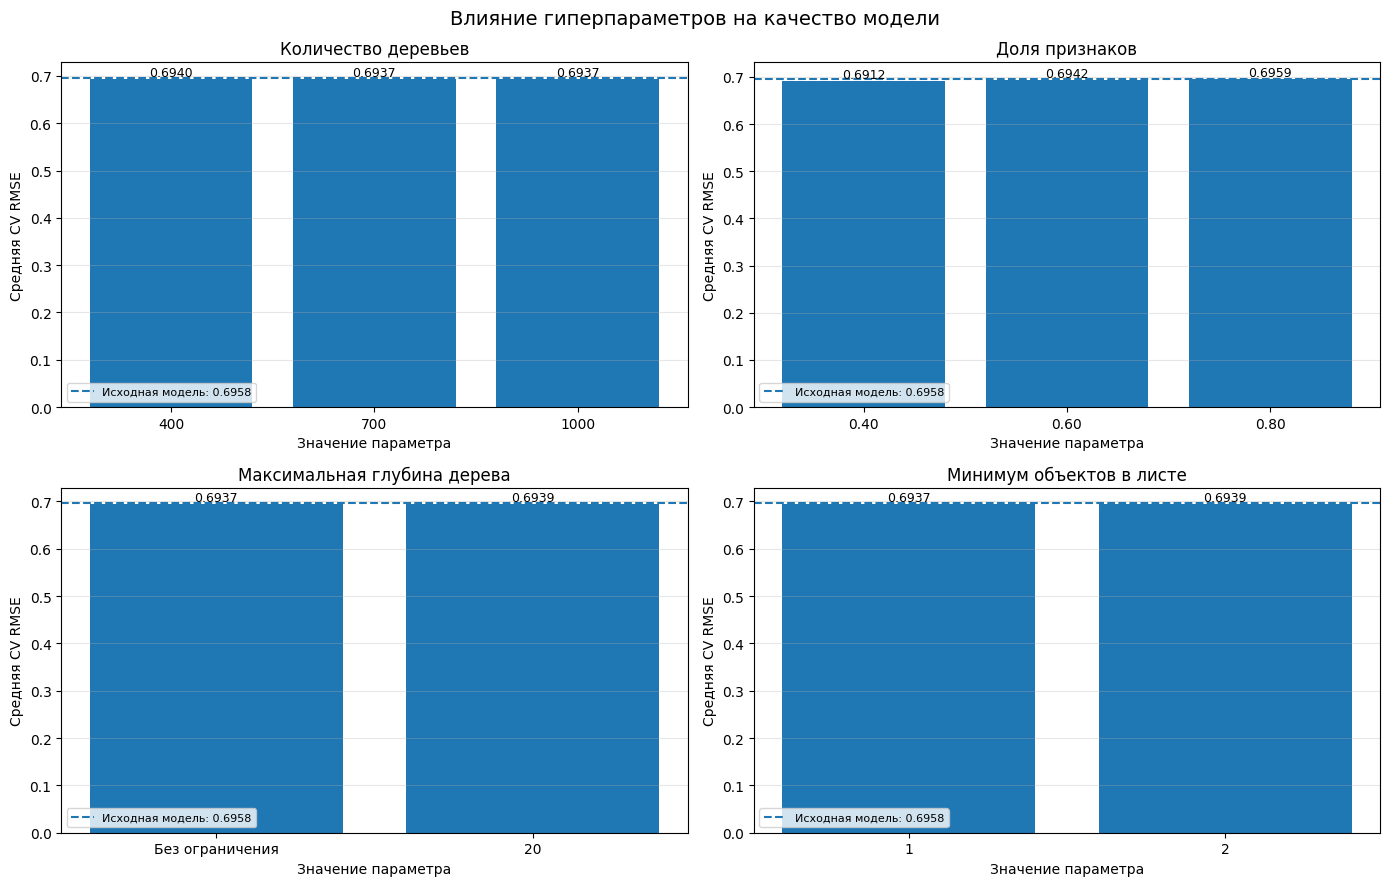

In [13]:
plot_results = grid_results.copy()

plot_results["n_estimators"] = plot_results["param_n_estimators"].astype(int)
plot_results["max_features"] = plot_results["param_max_features"].astype(float)
plot_results["min_samples_leaf"] = plot_results["param_min_samples_leaf"].astype(int)
plot_results["max_depth_label"] = plot_results["param_max_depth"].apply(
    lambda x: "Без ограничения" if pd.isna(x) else str(int(x))
)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

plots = [
    ("n_estimators", "Количество деревьев", axes[0, 0]),
    ("max_features", "Доля признаков", axes[0, 1]),
    ("max_depth_label", "Максимальная глубина дерева", axes[1, 0]),
    ("min_samples_leaf", "Минимум объектов в листе", axes[1, 1])
]

for column, title, ax in plots:
    summary = (
        plot_results.groupby(column, dropna=False)["mean_test_RMSE"]
        .mean()
        .reset_index()
    )

    if column == "max_depth_label":
        order = ["Без ограничения", "20"]
        summary[column] = pd.Categorical(
            summary[column],
            categories=order,
            ordered=True
        )
        summary = summary.sort_values(column)
        labels = summary[column].astype(str).tolist()
    else:
        summary = summary.sort_values(column)
        labels = [
            f"{value:.2f}" if column == "max_features" else str(int(value))
            for value in summary[column]
        ]

    bars = ax.bar(labels, summary["mean_test_RMSE"])

    ax.set_title(title)
    ax.set_xlabel("Значение параметра")
    ax.set_ylabel("Средняя CV RMSE")
    ax.grid(axis="y", alpha=0.3)

    for bar, value in zip(bars, summary["mean_test_RMSE"]):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{value:.4f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

    ax.axhline(
        baseline_cv_rmse,
        linestyle="--",
        linewidth=1.5,
        label=f"Исходная модель: {baseline_cv_rmse:.4f}"
    )

    ax.legend(fontsize=8)

plt.suptitle(
    "Влияние гиперпараметров на качество модели",
    fontsize=14
)

plt.tight_layout()
plt.show()


## 11. Финальная модель

После завершения подбора обучаются три модели: исходная модель, лучший вариант Grid Search и лучший вариант Random Search. Затем каждая модель один раз оценивается на отложенной тестовой выборке.


In [9]:
final_models = {
    "Исходная модель": baseline_model,
    "Grid Search": grid_search.best_estimator_,
    "Random Search": random_search.best_estimator_
}

cv_values = {
    "Исходная модель": baseline_cv_rmse,
    "Grid Search": grid_best_cv_rmse,
    "Random Search": random_best_cv_rmse
}

final_rows = []

for name, model in final_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    test_rmse = np.sqrt(mean_squared_error(y_test, pred))
    test_mae = mean_absolute_error(y_test, pred)

    final_rows.append({
        "Модель": name,
        "CV RMSE": cv_values[name],
        "Test RMSE": test_rmse,
        "Test MAE": test_mae
    })

final_results = pd.DataFrame(final_rows).sort_values("Test RMSE")
display(final_results.round(4))

,Модель,CV RMSE,Test RMSE,Test MAE
2,Random Search,0.6905,0.6582,0.5064
1,Grid Search,0.6903,0.6583,0.5069
0,Исходная модель,0.6958,0.6623,0.5086


## 12. Анализ результатов финальной оценки



In [10]:
baseline_row = final_results.loc[
    final_results["Модель"] == "Исходная модель"
].iloc[0]

comparison_rows = []

for model_name in ["Grid Search", "Random Search"]:
    row = final_results.loc[final_results["Модель"] == model_name].iloc[0]
    cv_change = baseline_row["CV RMSE"] - row["CV RMSE"]
    test_change = baseline_row["Test RMSE"] - row["Test RMSE"]

    comparison_rows.append({
        "Модель": model_name,
        "Изменение CV RMSE": cv_change,
        "Изменение Test RMSE": test_change,
        "Улучшение Test RMSE, %": (
            test_change / baseline_row["Test RMSE"] * 100
        )
    })

display(pd.DataFrame(comparison_rows).round(4))

best_cv_name = final_results.loc[final_results["CV RMSE"].idxmin(), "Модель"]
best_test_name = final_results.loc[final_results["Test RMSE"].idxmin(), "Модель"]

print(f"Лучшая модель по CV RMSE: {best_cv_name}.")
print(f"Лучшая модель по Test RMSE: {best_test_name}.")

if best_cv_name == best_test_name:
    print("Лучшая модель по кросс-валидации совпала с лучшей моделью на тесте.")
else:
    print(
        "Лучшая модель по кросс-валидации не совпала с лучшей моделью на тесте. "
        "Это возможно из-за различий между folds и отдельной тестовой выборкой."
    )

,Модель,Изменение CV RMSE,Изменение Test RMSE,"Улучшение Test RMSE, %"
0,Grid Search,0.0055,0.0039,0.5939
1,Random Search,0.0053,0.0041,0.6129


Лучшая модель по CV RMSE: Grid Search.
Лучшая модель по Test RMSE: Random Search.
Лучшая модель по кросс-валидации не совпала с лучшей моделью на тесте. Это возможно из-за различий между folds и отдельной тестовой выборкой.


## 13. Анализ устойчивости

Для каждой из трёх моделей рассчитывается RMSE отдельно на каждом из пяти folds. Дополнительно вычисляются среднее значение, стандартное отклонение, минимум и максимум.

Меньшее стандартное отклонение означает, что качество модели меньше меняется при смене разбиения. Две модели с одинаковым средним RMSE могут иметь разную устойчивость: у одной результаты folds могут быть близки друг к другу, а у другой — сильно различаться.

,Исходная модель,Grid Search,Random Search
Fold 1,0.7189,0.7127,0.7123
Fold 2,0.7107,0.7063,0.7063
Fold 3,0.6901,0.6829,0.6819
Fold 4,0.6740,0.6697,0.6716
Fold 5,0.6853,0.6800,0.6806


,Модель,Средняя CV RMSE,Стандартное отклонение,Минимум,Максимум
1,Grid Search,0.6903,0.0183,0.6697,0.7127
2,Random Search,0.6905,0.0177,0.6716,0.7123
0,Исходная модель,0.6958,0.0185,0.6740,0.7189


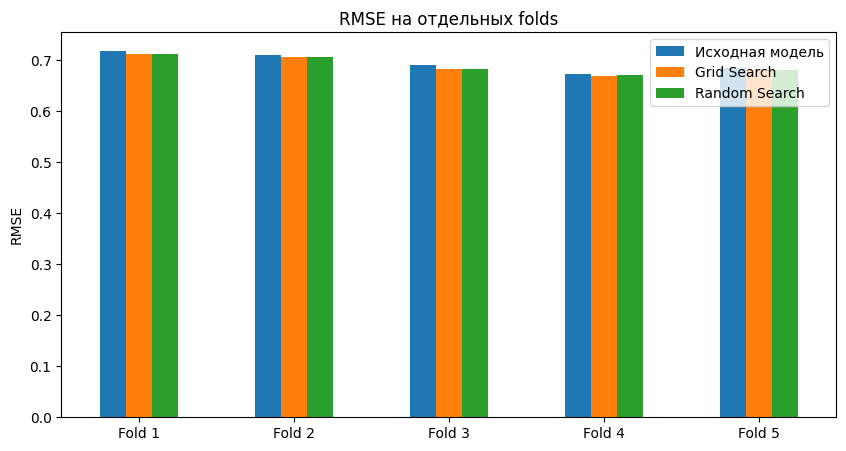

In [11]:
stability_models = {
    "Исходная модель": baseline_model,
    "Grid Search": grid_search.best_estimator_,
    "Random Search": random_search.best_estimator_
}

stability_rows = []
fold_table = pd.DataFrame(index=[f"Fold {i+1}" for i in range(N_SPLITS)])

for name, model in stability_models.items():
    scores = cross_validate(
        model,
        X_train, y_train,
        cv=cv,
        scoring=SCORING,
        n_jobs=1
    )["test_score"]
    fold_rmse = -scores
    fold_table[name] = fold_rmse

    stability_rows.append({
        "Модель": name,
        "Средняя CV RMSE": fold_rmse.mean(),
        "Стандартное отклонение": fold_rmse.std(ddof=1),
        "Минимум": fold_rmse.min(),
        "Максимум": fold_rmse.max()
    })

display(fold_table.round(4))
stability_results = pd.DataFrame(stability_rows).sort_values("Средняя CV RMSE")
display(stability_results.round(4))

fold_table.plot(kind="bar", figsize=(10, 5))
plt.ylabel("RMSE")
plt.title("RMSE на отдельных folds")
plt.xticks(rotation=0)
plt.show()

## 14. Итоговый вывод

В ходе лабораторной работы была проведена оптимизация гиперпараметров модели Random Forest с помощью Grid Search и Random Search.

Оба метода улучшили результат исходной модели. Лучший Test RMSE показал Random Search — 0.6582 против 0.6623 у исходной модели. Улучшение составило 0.61%. Grid Search показал Test RMSE = 0.6583.

Оба метода проверили по 36 комбинаций. Random Search выполнился быстрее: 217.4 секунды против 245.5 секунды у Grid Search.

По результатам пяти фолдов Random Search также показал наименьшее стандартное отклонение RMSE — 0.0177, что говорит о немного большей стабильности.

Таким образом, Random Search оказался наиболее удачным методом в данном эксперименте. Тестовая выборка использовалась только для финальной оценки, а подбор параметров выполнялся с помощью кросс-валидации.